In [29]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [30]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
import os
from skimage.io import imread
from skimage.transform import resize
from keras.models import Sequential
from keras.layers import Conv2D,MaxPool2D,Flatten,Dense

In [31]:
os.listdir('/content/drive/MyDrive/Brain_Tumor')

['Training', 'Testing']

In [32]:
os.listdir('/content/drive/MyDrive/Brain_Tumor/Testing')

['pituitary', 'notumor', 'meningioma', 'glioma']

In [33]:
os.listdir('/content/drive/MyDrive/Brain_Tumor/Training')

['glioma', 'pituitary', 'notumor', 'meningioma']

In [34]:
#Count of images
print('Training')
print('glioma')
print(len(os.listdir('/content/drive/MyDrive/Brain_Tumor/Training/glioma')))
print('meningioma')
print(len(os.listdir('/content/drive/MyDrive/Brain_Tumor/Training/meningioma')))
print('notumor')
print(len(os.listdir('/content/drive/MyDrive/Brain_Tumor/Training/notumor')))
print('pituitary')
print(len(os.listdir('/content/drive/MyDrive/Brain_Tumor/Training/pituitary')))

print()
print('Testing')
print('glioma')
print(len(os.listdir('/content/drive/MyDrive/Brain_Tumor/Testing/glioma')))
print('meningioma')
print(len(os.listdir('/content/drive/MyDrive/Brain_Tumor/Testing/meningioma')))
print('notumor')
print(len(os.listdir('/content/drive/MyDrive/Brain_Tumor/Testing/notumor')))
print('pituitary')
print(len(os.listdir('/content/drive/MyDrive/Brain_Tumor/Testing/pituitary')))

Training
glioma
1287
meningioma
1319
notumor
1574
pituitary
1349

Testing
glioma
300
meningioma
306
notumor
405
pituitary
300


In [35]:
#Sorting files because of wrong order
train_data = sorted(os.listdir('/content/drive/MyDrive/Brain_Tumor/Training'))
print('training_sorted',train_data)
test_data = sorted(os.listdir('/content/drive/MyDrive/Brain_Tumor/Testing'))
print('Testing_sorted',test_data)

training_sorted ['glioma', 'meningioma', 'notumor', 'pituitary']
Testing_sorted ['glioma', 'meningioma', 'notumor', 'pituitary']


In [36]:
datadir = '/content/drive/MyDrive/Brain_Tumor/Training'

In [37]:
x_train = []
y_train = []

In [44]:
for i in train_data:
  print('Loading train data',i)
  path = os.path.join(datadir,i)
  for img in os.listdir(path):
    img_read = imread(os.path.join(path,img))
    img_res = resize(img_read,(150,150,1))
    x_train.append(img_res)
    y_train.append(train_data.index(i))
print('Loading completed')

Loading train data glioma
Loading train data meningioma
Loading train data notumor
Loading train data pituitary
Loading completed


In [41]:
test_dir = '/content/drive/MyDrive/Brain_Tumor/Testing'

In [42]:
x_test = []
y_test = []

In [43]:
for j in test_data:
  print('Loading test data',j)
  path = os.path.join(test_dir,j)
  for img in os.listdir(path):
    img_read = imread(os.path.join(path,img))
    img_res = resize(img_read,(150,150,1))
    x_test.append(img_res)
    y_test.append(test_data.index(j))
print('Loading completed')

Loading test data glioma
Loading test data meningioma
Loading test data notumor
Loading test data pituitary
Loading completed


In [46]:
#Coverting input and output to arrays
x_train = np.array(x_train)
x_test = np.array(x_test)
y_train = np.array(y_train)
y_test = np.array(y_test)

In [50]:
#Building the architecure of model
model = Sequential()
model.add(Conv2D(32,(3,3),input_shape = (150,150,1),activation='relu'))
model.add(MaxPool2D(2,2))
model.add(Flatten())
model.add(Dense(100,activation='relu'))
model.add(Dense(50,activation='relu'))
model.add(Dense(4,activation='softmax'))

In [51]:
model.compile(optimizer='adam',loss='sparse_categorical_crossentropy',metrics=['accuracy'])

In [52]:
model.fit(x_train,y_train,epochs=100,batch_size=100)

Epoch 1/100
148/148 ━━━━━━━━━━━━━━━━━━━━ 16s 59ms/step - accuracy: 0.7919 - loss: 0.5252
Epoch 2/100
148/148 ━━━━━━━━━━━━━━━━━━━━ 5s 32ms/step - accuracy: 0.9618 - loss: 0.1223
Epoch 3/100
148/148 ━━━━━━━━━━━━━━━━━━━━ 5s 32ms/step - accuracy: 0.9928 - loss: 0.0343
Epoch 4/100
148/148 ━━━━━━━━━━━━━━━━━━━━ 5s 33ms/step - accuracy: 0.9995 - loss: 0.0071
Epoch 5/100
148/148 ━━━━━━━━━━━━━━━━━━━━ 5s 32ms/step - accuracy: 1.0000 - loss: 0.0028
Epoch 6/100
148/148 ━━━━━━━━━━━━━━━━━━━━ 5s 32ms/step - accuracy: 1.0000 - loss: 0.0012
Epoch 7/100
148/148 ━━━━━━━━━━━━━━━━━━━━ 5s 33ms/step - accuracy: 1.0000 - loss: 7.9788e-04
Epoch 8/100
148/148 ━━━━━━━━━━━━━━━━━━━━ 5s 32ms/step - accuracy: 1.0000 - loss: 5.5787e-04
Epoch 9/100
148/148 ━━━━━━━━━━━━━━━━━━━━ 5s 33ms/step - accuracy: 1.0000 - loss: 3.3734e-04
Epoch 10/100
148/148 ━━━━━━━━━━━━━━━━━━━━ 5s 33ms/step - accuracy: 1.0000 - loss: 2.1229e-04
Epoch 11/100
148/148 ━━━━━━━━━━━━━━━━━━━━ 5s 32ms/step - accuracy: 1.0000 - loss: 1.4584e-04
Epoch 12/

In [58]:
model.evaluate(x_test,y_test,batch_size=100)

14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.9535 - loss: 0.4138


[0.4138191044330597, 0.9534706473350525]

In [60]:
y_pred = model.predict(x_test[:15])
final_result = np.argmax(y_pred,axis=1)
print(final_result)
print(y_test[:15])

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step
[1 0 0 0 0 0 0 0 0 0 0 1 0 0 0]
[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]


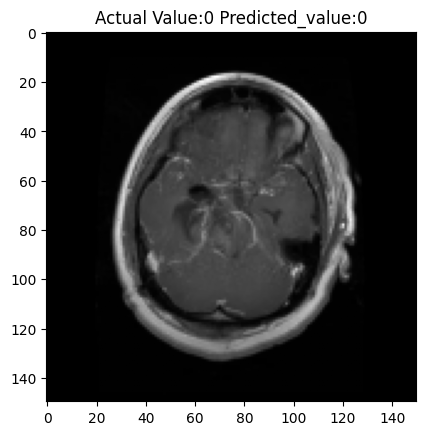

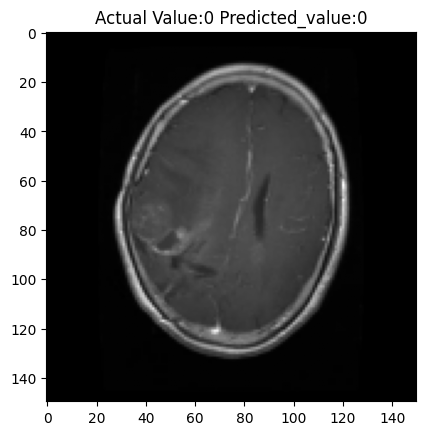

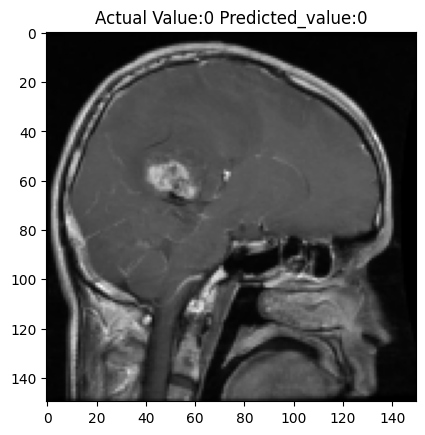

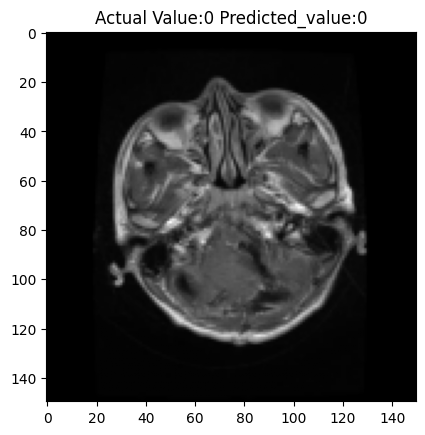

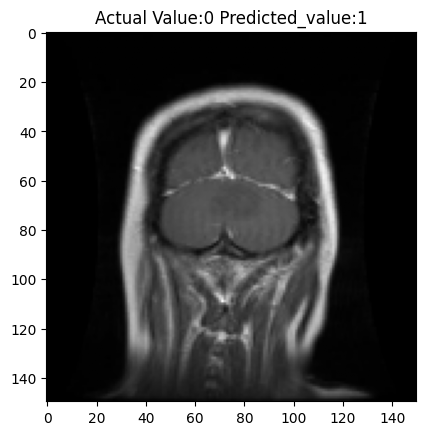

...

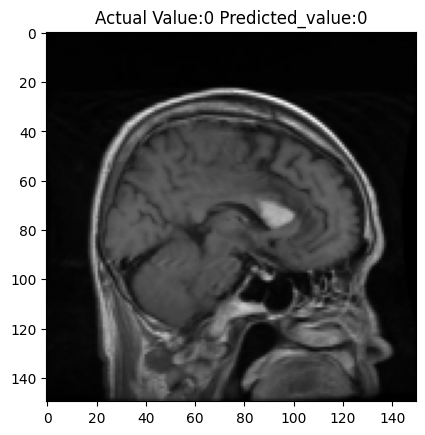

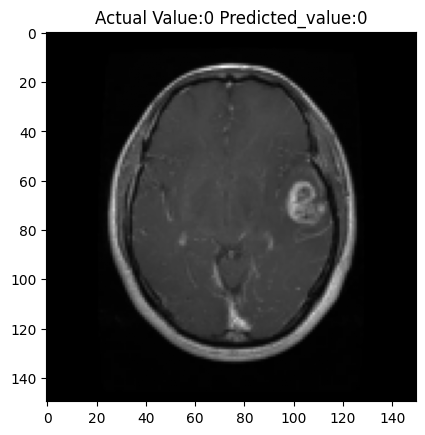

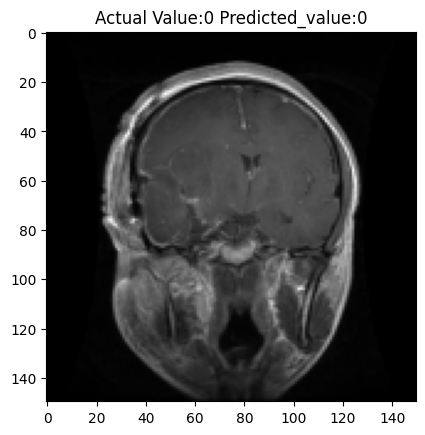

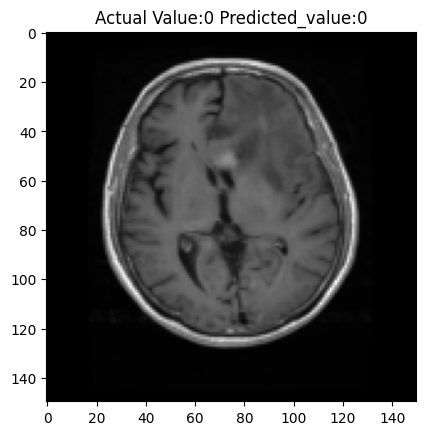

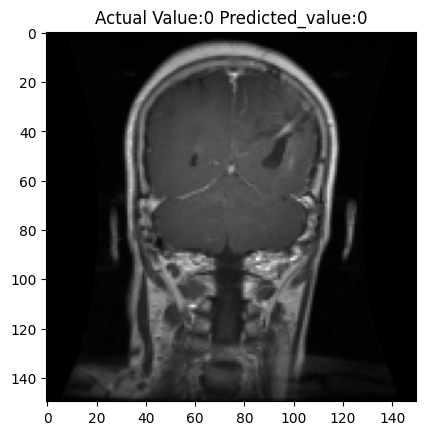

In [61]:
#Another method for prediction
for i in range(150,251):
  y_pred = model.predict(x_test[i].reshape(1,150,150,1),verbose=0)
  output = np.argmax(y_pred)

  plt.imshow(x_test[i],cmap='gray')
  plt.title(f"Actual Value:{y_test[i]} Predicted_value:{output}")
  plt.show()